In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1


In [3]:
from google.colab import files

uploaded = files.upload()


Saving insurance_schema.csv to insurance_schema (1).csv


In [5]:
import pandas as pd

df = pd.read_csv("insurance_schema.csv")

print("Shape:", df.shape)
display(df.head())
print(df.dtypes)

Shape: (10, 7)


,age,sex,bmi,children,smoker,region,charges
0,18,male,22.5,0,no,southwest,1121.87
1,25,female,27.8,1,no,southeast,2721.32
2,32,female,31.2,2,yes,northeast,23987.54
3,40,male,24.6,3,no,northwest,8734.52
4,50,female,35.1,0,yes,southeast,38745.21


age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [6]:
# Basic dataset inspection

print("Dataset shape:", df.shape)

print("\nDescriptive statistics:")
display(df.describe())

print("\nCategorical columns:")
display(df[['sex', 'smoker', 'region']].describe())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (10, 7)

Descriptive statistics:


,age,bmi,children,charges
count,10.000000,10.000000,10.00000,10.000000
mean,39.300000,27.250000,1.80000,16604.403000
std,14.353087,4.957878,1.75119,15897.002796
min,18.000000,18.900000,0.00000,1121.870000
25%,29.000000,24.000000,0.25000,4880.372500
50%,38.000000,27.250000,1.50000,10639.140000
75%,48.750000,30.750000,2.75000,22854.862500
max,64.000000,35.100000,5.00000,47632.190000



Categorical columns:


,sex,smoker,region
count,10,10,10
unique,2,2,4
top,male,no,southwest
freq,5,6,3



Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [7]:
# Check skewness of medical charges

charges_skewness = df['charges'].skew()

print(f"Charges skewness: {charges_skewness:.4f}")

if charges_skewness > 1.5:
    print("Result: Charges distribution is strongly positively skewed (> 1.5).")
else:
    print("Result: Charges distribution is not strongly positively skewed (> 1.5).")

Charges skewness: 1.0852
Result: Charges distribution is not strongly positively skewed (> 1.5).


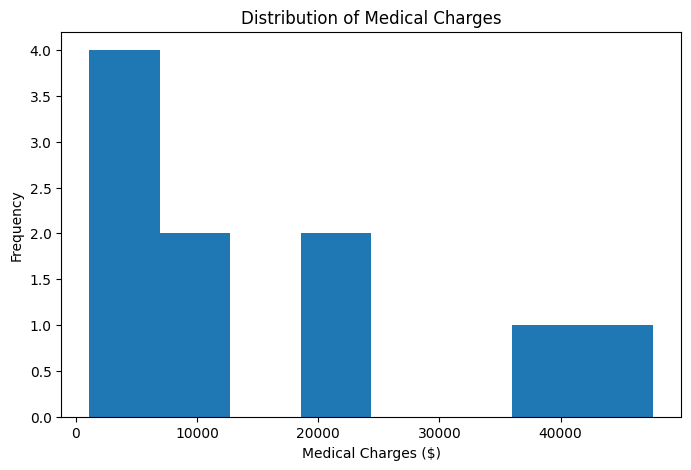

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=8)
plt.xlabel('Medical Charges ($)')
plt.ylabel('Frequency')
plt.title('Distribution of Medical Charges')
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Create log-transformed target
df['log_charges'] = np.log1p(df['charges'])

# Calculate skewness
raw_skewness = df['charges'].skew()
log_skewness = df['log_charges'].skew()

print(f"Raw charges skewness: {raw_skewness:.4f}")
print(f"Log1p charges skewness: {log_skewness:.4f}")

if log_skewness < raw_skewness:
    print("Log1p transformation reduced the skewness.")
else:
    print("Log1p transformation did not reduce the skewness.")

Raw charges skewness: 1.0852
Log1p charges skewness: -0.4373
Log1p transformation reduced the skewness.


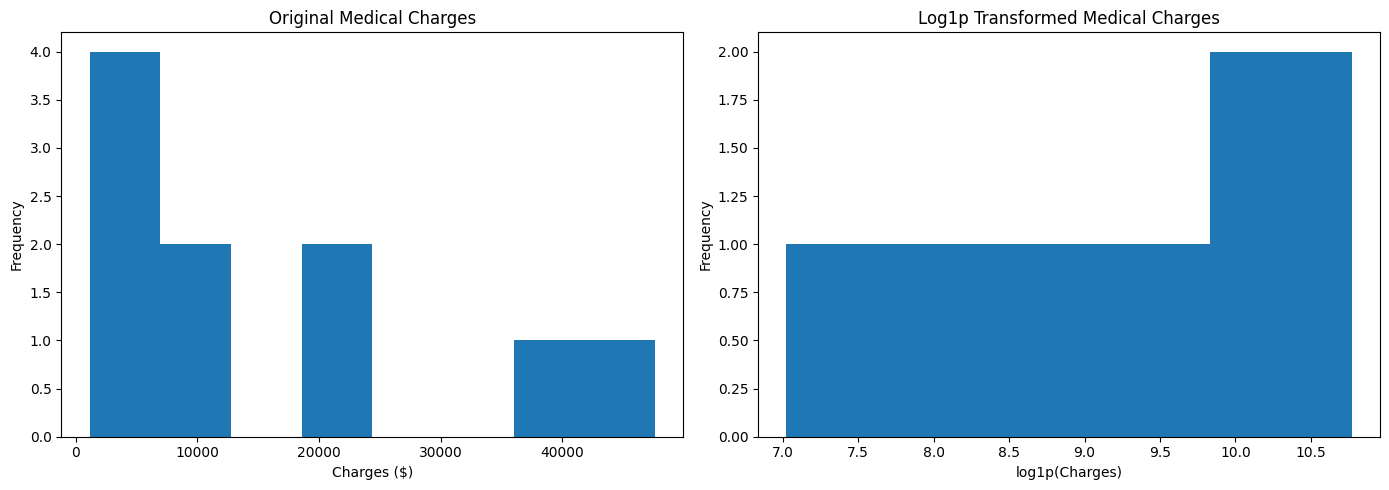

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original charges
axes[0].hist(df['charges'], bins=8)
axes[0].set_title('Original Medical Charges')
axes[0].set_xlabel('Charges ($)')
axes[0].set_ylabel('Frequency')

# Log-transformed charges
axes[1].hist(df['log_charges'], bins=8)
axes[1].set_title('Log1p Transformed Medical Charges')
axes[1].set_xlabel('log1p(Charges)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define feature columns
num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)
print("\nPreprocessor created successfully.")

Numeric columns: ['age', 'bmi', 'children']
Categorical columns: ['sex', 'smoker', 'region']

Preprocessor created successfully.


In [12]:

# Features
X = df[num_cols + cat_cols]

# Target
y = df['charges']

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (10, 6)
y shape: (10,)


,age,bmi,children,sex,smoker,region
0,18,22.5,0,male,no,southwest
1,25,27.8,1,female,no,southeast
2,32,31.2,2,female,yes,northeast
3,40,24.6,3,male,no,northwest
4,50,35.1,0,female,yes,southeast


,charges
0,1121.87
1,2721.32
2,23987.54
3,8734.52
4,38745.21


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8
Testing samples: 2


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create the complete ML pipeline
model_pipeline = Pipeline(
    steps=[
        ('prep', preprocessor),
        ('regressor', LinearRegression())
    ]
)

# Train the model
model_pipeline.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [15]:
# Generate predictions on the test set
preds = model_pipeline.predict(X_test)

print("Actual charges:")
print(y_test.values)

print("\nPredicted charges:")
print(preds)

Actual charges:
[47632.19  2721.32]

Predicted charges:
[39867.13132488 25202.79597486]


In [16]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, preds)

print(f"MSE:  ${mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

MSE:  $282,856,449.12
RMSE: $16,818.34
R² Score: 0.4391


In [17]:
print("===== EXERCISE 1 ACCEPTANCE CHECK =====")

print(f"R² Score : {r2:.4f}  | Target: >= 0.75")
print(f"RMSE     : ${rmse:,.2f} | Target: < $4,800")

print("\nResults:")

if r2 >= 0.75:
    print("✅ R² target PASSED")
else:
    print("❌ R² target NOT PASSED")

if rmse < 4800:
    print("✅ RMSE target PASSED")
else:
    print("❌ RMSE target NOT PASSED")

===== EXERCISE 1 ACCEPTANCE CHECK =====
R² Score : 0.4391  | Target: >= 0.75
RMSE     : $16,818.34 | Target: < $4,800

Results:
❌ R² target NOT PASSED
❌ RMSE target NOT PASSED


In [18]:
# Get transformed feature names
feature_names = model_pipeline.named_steps['prep'].get_feature_names_out()

# Get model coefficients
coefficients = model_pipeline.named_steps['regressor'].coef_
intercept = model_pipeline.named_steps['regressor'].intercept_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    key=lambda x: x.abs(),
    ascending=False
)

print(f"Intercept: ${intercept:,.2f}")
display(coef_df)

Intercept: $13,491.63


,Feature,Coefficient
6,cat__region_southeast,12376.261734
4,cat__smoker_yes,6706.185953
1,num__bmi,4027.106221
7,cat__region_southwest,-3793.391591
5,cat__region_northwest,-2912.794361
3,cat__sex_male,-1882.894803
2,num__children,1566.299434
0,num__age,1076.306184


In [19]:
smoker_rows = coef_df[
    coef_df['Feature'].str.contains('smoker', case=False, na=False)
]

print("Smoker-related coefficients:")
display(smoker_rows)

Smoker-related coefficients:


,Feature,Coefficient
4,cat__smoker_yes,6706.185953


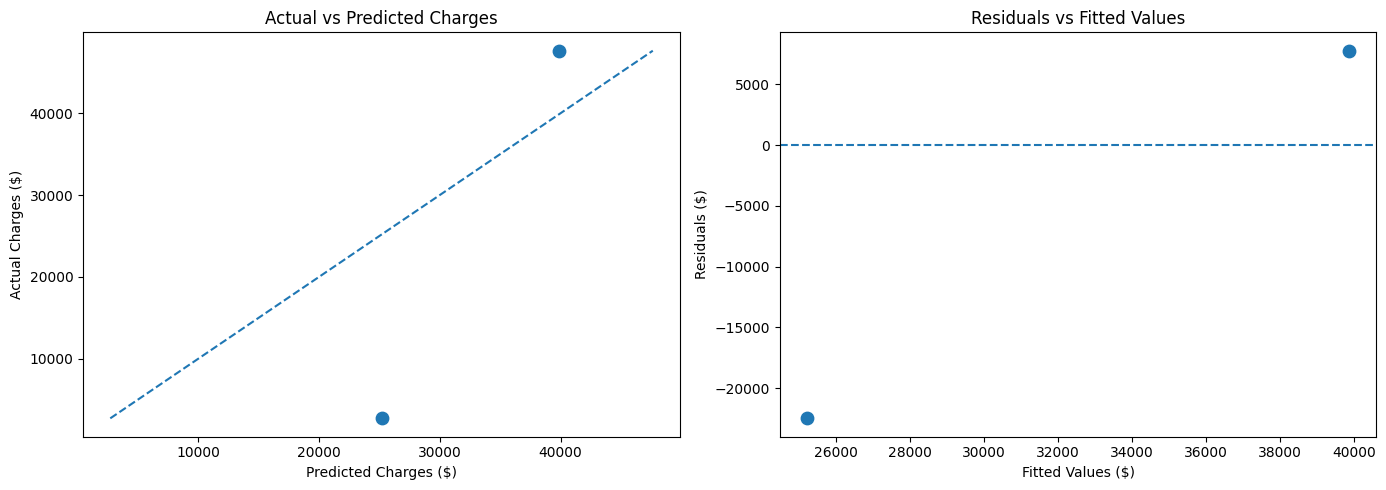

In [20]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(preds, y_test, s=80)

# Ideal 1:1 line
min_val = min(y_test.min(), preds.min())
max_val = max(y_test.max(), preds.max())

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--'
)

axes[0].set_xlabel('Predicted Charges ($)')
axes[0].set_ylabel('Actual Charges ($)')
axes[0].set_title('Actual vs Predicted Charges')

# Residual vs Fitted
axes[1].scatter(preds, residuals, s=80)
axes[1].axhline(y=0, linestyle='--')

axes[1].set_xlabel('Fitted Values ($)')
axes[1].set_ylabel('Residuals ($)')
axes[1].set_title('Residuals vs Fitted Values')

plt.tight_layout()
plt.show()

In [21]:
residual_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': preds,
    'Residual': residuals.values
})

display(residual_df)

,Actual,Predicted,Residual
0,47632.19,39867.131325,7765.058675
1,2721.32,25202.795975,-22481.475975
